<a href="https://colab.research.google.com/github/gnanasiri13/EMAIL_SPAM_DETECTION/blob/main/email_spam_detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Email Spam Detection Using Text Analytics

**Objective**: Classify emails as Spam or Ham using PySpark, TF-IDF and Multinomial Naive Bayes.

# Install Required Libraries

**Install PySpark**


In [ ]:
!pip install pyspark -q

**Import libraries**

In [ ]:
from pyspark.sql import SparkSession
from pyspark.sql.functions import col, length

from pyspark.ml import Pipeline
from pyspark.ml.feature import (
    RegexTokenizer,
    StopWordsRemover,
    HashingTF,
    IDF
)
from pyspark.ml.classification import NaiveBayes
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Create Spark Session

**Start Apache Spark**

In [ ]:
spark = (
    SparkSession.builder
    .appName("Email Spam Detection")
    .master("local[*]")
    .getOrCreate()
)

spark.sparkContext.setLogLevel("ERROR")

print("Spark Version:", spark.version)
print("Spark started successfully!")

Spark Version: 4.0.5
Spark started successfully!


# Load the Dataset

**Load dataset**

In [ ]:
df = spark.read.csv(
    "spam_ham_dataset.csv",
    header=True,
    inferSchema=True,
    multiLine=True,
    escape='"'
)

df.show(5, truncate=80)

+----+-----+--------------------------------------------------------------------------------+---------+
| _c0|label|                                                                            text|label_num|
+----+-----+--------------------------------------------------------------------------------+---------+
| 605|  ham|Subject: enron methanol ; meter # : 988291\nthis is a follow up to the note i...|        0|
|2349|  ham|Subject: hpl nom for january 9 , 2001\n( see attached file : hplnol 09 . xls ...|        0|
|3624|  ham|Subject: neon retreat\nho ho ho , we ' re around to that most wonderful time ...|        0|
|4685| spam|Subject: photoshop , windows , office . cheap . main trending\nabasements dar...|        1|
|2030|  ham|Subject: re : indian springs\nthis deal is to book the teco pvr revenue . it ...|        0|
+----+-----+--------------------------------------------------------------------------------+---------+
only showing top 5 rows


# Data Preprocessing

**Display schema**

In [ ]:
df.printSchema()

root
 |-- _c0: integer (nullable = true)
 |-- label: string (nullable = true)
 |-- text: string (nullable = true)
 |-- label_num: integer (nullable = true)



**Clean the dataset**

In [ ]:
df = df.select(
    col("label"),
    col("text"),
    col("label_num").cast("double").alias("label_num")
)

df = df.dropna()
df = df.dropDuplicates(["text"])

print("Total Emails:", df.count())

df.groupBy("label").count().show()

Total Emails: 4993
+-----+-----+
|label|count|
+-----+-----+
|  ham| 3531|
| spam| 1462|
+-----+-----+



# Exploratory Data Analysis

**Ham vs Spam Distribution**

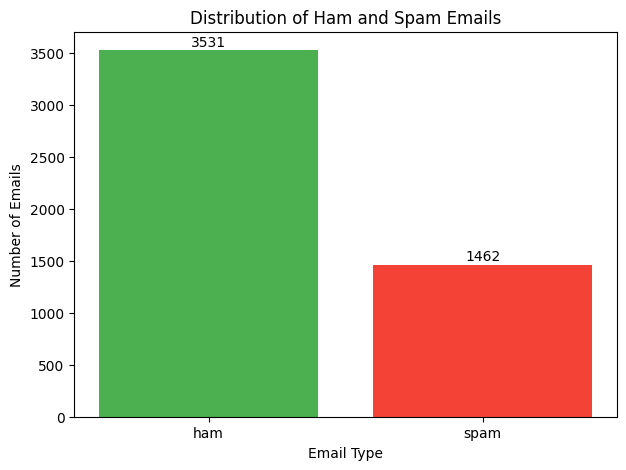

In [ ]:
class_data = df.groupBy("label").count().toPandas()

plt.figure(figsize=(7, 5))

plt.bar(
    class_data["label"],
    class_data["count"],
    color=["#4CAF50", "#F44336"]
)

plt.title("Distribution of Ham and Spam Emails")
plt.xlabel("Email Type")
plt.ylabel("Number of Emails")

for i, value in enumerate(class_data["count"]):
    plt.text(i, value + 40, str(value), ha="center")

plt.show()

**Email length analysis**

In [ ]:
df = df.withColumn(
    "text_length",
    length(col("text"))
)

df.groupBy("label").avg("text_length").show()

+-----+------------------+
|label|  avg(text_length)|
+-----+------------------+
|  ham| 977.0897762673463|
| spam|1227.7462380300958|
+-----+------------------+



**Average Email Length**

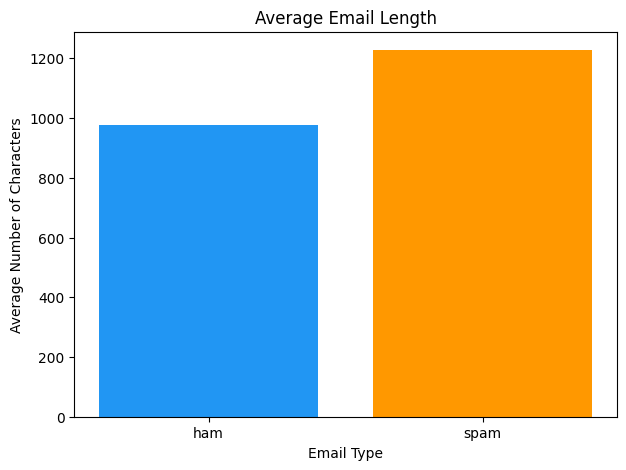

In [ ]:
length_data = (
    df.groupBy("label")
    .avg("text_length")
    .toPandas()
)

plt.figure(figsize=(7, 5))

plt.bar(
    length_data["label"],
    length_data["avg(text_length)"],
    color=["#2196F3", "#FF9800"]
)

plt.title("Average Email Length")
plt.xlabel("Email Type")
plt.ylabel("Average Number of Characters")

plt.show()


# Train-Test Split

Split dataset into:

*  80% Training
*  20% Testing




**Split Data**

In [ ]:
train_data, test_data = df.randomSplit(
    [0.8, 0.2],
    seed=42
)

train_count = train_data.count()
test_count = test_data.count()

print("Training Emails:", train_count)
print("Testing Emails :", test_count)

Training Emails: 4057
Testing Emails : 936


# Text Preprocessing

**Tokenization**

In [ ]:
tokenizer = RegexTokenizer(
    inputCol="text",
    outputCol="words",
    pattern="\\W+"
)


**Remove stop words**

In [ ]:
stopwords_remover = StopWordsRemover(
    inputCol="words",
    outputCol="filtered_words"
)

# Feature Extraction Using TF-IDF

**HashingTF**

In [ ]:
hashing_tf = HashingTF(
    inputCol="filtered_words",
    outputCol="raw_features",
    numFeatures=10000
)

**IDF**

In [ ]:
idf = IDF(
    inputCol="raw_features",
    outputCol="features"
)

# Naive Bayes Classification

**Naive Bayes classifier**

Use: Multinomial Naive Bayes

Classes:

*  0 = Ham
*  1 = Spam



In [ ]:
naive_bayes = NaiveBayes(
    featuresCol="features",
    labelCol="label_num",
    predictionCol="prediction",
    probabilityCol="probability",
    smoothing=1.0,
    modelType="multinomial"
)

# Build Spark ML Pipeline

**Create Spark ML pipeline**

Pipeline:

Email → Tokenization → Stop Words → HashingTF → IDF → Naive Bayes → Prediction

In [ ]:
pipeline = Pipeline(
    stages=[
        tokenizer,
        stopwords_remover,
        hashing_tf,
        idf,
        naive_bayes
    ]
)

print("Pipeline created successfully!")

Pipeline created successfully!


# Model Training

**Train the model**

In [ ]:
print("Training model...")

model = pipeline.fit(train_data)

print("Model trained successfully!")

Training model...
Model trained successfully!


**Predict test data**

In [ ]:
predictions = model.transform(test_data)

predictions.select(
    "label",
    "label_num",
    "prediction",
    "probability",
    "text"
).show(
    10,
    truncate=70
)

+-----+---------+----------+----------------------------+----------------------------------------------------------------------+
|label|label_num|prediction|                 probability|                                                                  text|
+-----+---------+----------+----------------------------+----------------------------------------------------------------------+
|  ham|      0.0|       0.0| [1.0,6.86653687659265E-103]|Subject: - - - - - - - - - - - - - - - - - - - - - - forwarded by a...|
|  ham|      0.0|       1.0|[8.838004516703879E-147,1.0]|Subject: 10 % off ! our gift to you !\n[ image ] [ image ] [ image ...|
|  ham|      0.0|       0.0| [1.0,1.606407985854343E-48]|Subject: 10 / 2000 - days 6 and 19 ( 98 - 0439 )\nthe above referen...|
|  ham|      0.0|       0.0|[1.0,2.194938756200909E-235]|Subject: 2 nd rev dec . 1999 josey ranch nom\n- - - - - - - - - - -...|
|  ham|      0.0|       0.0|[1.0,2.9714700736077805E-23]|Subject: 2000 plan allocations\ni ' ve g

# Model Evaluation

**Calculate model metrics**

In [ ]:
def evaluate(metric):

    evaluator = MulticlassClassificationEvaluator(
        labelCol="label_num",
        predictionCol="prediction",
        metricName=metric
    )

    return evaluator.evaluate(predictions)


accuracy = evaluate("accuracy")
precision = evaluate("weightedPrecision")
recall = evaluate("weightedRecall")
f1 = evaluate("f1")

print("Accuracy :", round(accuracy * 100, 2), "%")
print("Precision:", round(precision * 100, 2), "%")
print("Recall   :", round(recall * 100, 2), "%")
print("F1 Score :", round(f1 * 100, 2), "%")

Accuracy : 96.37 %
Precision: 96.44 %
Recall   : 96.37 %
F1 Score : 96.39 %


**Model Performance**

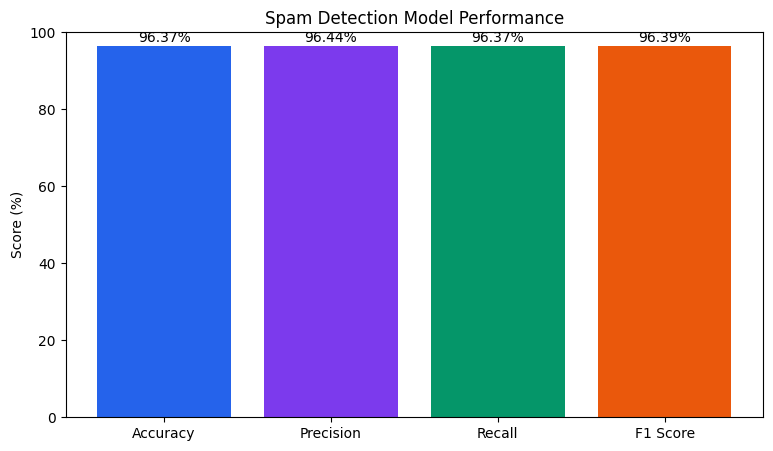

In [ ]:
metrics_names = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score"
]

metrics_values = [
    accuracy * 100,
    precision * 100,
    recall * 100,
    f1 * 100
]

plt.figure(figsize=(9, 5))

bars = plt.bar(
    metrics_names,
    metrics_values,
    color=[
        "#2563EB",
        "#7C3AED",
        "#059669",
        "#EA580C"
    ]
)

plt.title("Spam Detection Model Performance")
plt.ylabel("Score (%)")
plt.ylim(0, 100)

for bar, value in zip(bars, metrics_values):

    plt.text(
        bar.get_x() + bar.get_width()/2,
        value + 1,
        f"{value:.2f}%",
        ha="center"
    )

plt.show()


**Confusion Matrix Values**

In [ ]:
tp = predictions.filter(
    (col("label_num") == 1.0) &
    (col("prediction") == 1.0)
).count()

fn = predictions.filter(
    (col("label_num") == 1.0) &
    (col("prediction") == 0.0)
).count()

fp = predictions.filter(
    (col("label_num") == 0.0) &
    (col("prediction") == 1.0)
).count()

tn = predictions.filter(
    (col("label_num") == 0.0) &
    (col("prediction") == 0.0)
).count()

print("True Positive :", tp)
print("True Negative :", tn)
print("False Positive:", fp)
print("False Negative:", fn)

True Positive : 277
True Negative : 625
False Positive: 23
False Negative: 11


**Confusion Matrix**

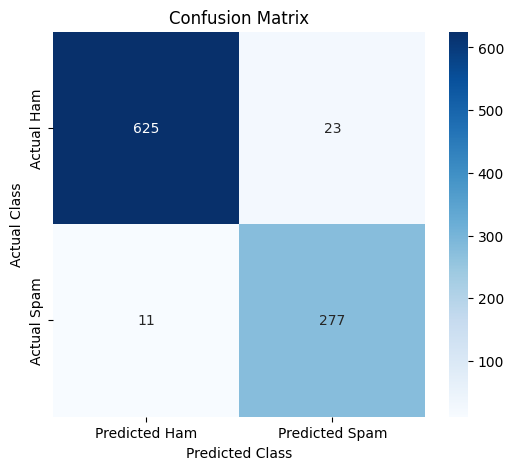

In [ ]:
confusion = [
    [tn, fp],
    [fn, tp]
]

plt.figure(figsize=(6, 5))

sns.heatmap(
    confusion,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "Predicted Ham",
        "Predicted Spam"
    ],
    yticklabels=[
        "Actual Ham",
        "Actual Spam"
    ]
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.show()

**Spam-specific recall**

In [ ]:
spam_recall = tp / (tp + fn)

print(
    "Spam Detection Recall:",
    round(spam_recall * 100, 2),
    "%"
)

Spam Detection Recall: 96.18 %


# Custom Email Testing

**Test your own email**

In [ ]:
def predict_email(email):

    custom_df = spark.createDataFrame(
        [(email,)],
        ["text"]
    )

    result = (
        model.transform(custom_df)
        .select(
            "prediction",
            "probability"
        )
        .first()
    )

    prediction = result["prediction"]
    probability = result["probability"]

    ham_probability = float(probability[0]) * 100
    spam_probability = float(probability[1]) * 100

    print("Email:")
    print(email)

    print()

    if prediction == 1.0:
        print("Prediction: SPAM 🚨")
    else:
        print("Prediction: HAM ✅")

    print(
        "Ham Probability:",
        round(ham_probability, 2),
        "%"
    )

    print(
        "Spam Probability:",
        round(spam_probability, 2),
        "%"
    )


**Test Spam**

In [ ]:
predict_email(
    """
    Congratulations!

    You have won $1000.
    Click here immediately to claim your free prize.
    """
)

Email:

    Congratulations!

    You have won $1000.
    Click here immediately to claim your free prize.
    

Prediction: SPAM 🚨
Ham Probability: 0.0 %
Spam Probability: 100.0 %


**Test Ham**

In [ ]:
predict_email(
    """
    Hi,

    Can we have the project review meeting
    tomorrow morning at 10 AM?

    Thanks.
    """
)

Email:

    Hi,

    Can we have the project review meeting
    tomorrow morning at 10 AM?

    Thanks.
    

Prediction: HAM ✅
Ham Probability: 100.0 %
Spam Probability: 0.0 %


# Results and Discussion

In [ ]:
print("=" * 55)
print("EMAIL SPAM DETECTION - FINAL RESULTS")
print("=" * 55)

print("Total Emails :", df.count())
print("Training     :", train_count)
print("Testing      :", test_count)

print()

print("Accuracy     :", round(accuracy * 100, 2), "%")
print("Precision    :", round(precision * 100, 2), "%")
print("Recall       :", round(recall * 100, 2), "%")
print("F1 Score     :", round(f1 * 100, 2), "%")
print("Spam Recall  :", round(spam_recall * 100, 2), "%")

print()

print("Algorithm    : Multinomial Naive Bayes")
print("Framework    : Apache Spark / PySpark")
print("Technique    : TF-IDF Text Analytics")

print("=" * 55)

EMAIL SPAM DETECTION - FINAL RESULTS
Total Emails : 4993
Training     : 4057
Testing      : 936

Accuracy     : 96.37 %
Precision    : 96.44 %
Recall       : 96.37 %
F1 Score     : 96.39 %
Spam Recall  : 96.18 %

Algorithm    : Multinomial Naive Bayes
Framework    : Apache Spark / PySpark
Technique    : TF-IDF Text Analytics


# Conclusion

The Email Spam Detection Using Text Analytics project successfully classified emails as spam or ham using Apache Spark/PySpark, TF-IDF, and the Multinomial Naive Bayes algorithm. The model was trained on 4,057 emails and tested on 936 emails from a total dataset of 4,993 emails.

The model achieved 96.37% accuracy, 96.44% precision, 96.37% recall, and an F1-score of 96.39%. A spam recall of 96.18% indicates that the system successfully identified the large majority of actual spam emails.

Overall, the results demonstrate that combining Spark-based text processing, TF-IDF feature extraction, and Multinomial Naive Bayes provides an effective and scalable approach for automated email spam detection.